<a href="https://colab.research.google.com/github/James1-loki/alphagroup/blob/main/02_llm_architecture_anatomy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [17]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [18]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

Original text:

I love running in the morning before work. Coffee is essential. 
I enjoy reading science fiction and coding in Python. 
Weekends are for family time and outdoor activities.


Tokens (28 total):
['i', 'love', 'running', 'in', 'the', 'morning', 'before', 'work', 'coffee', 'is', 'essential', 'i', 'enjoy', 'reading', 'science', 'fiction', 'and', 'coding', 'in', 'python'] ...

Most common tokens:
  i: 2
  in: 2
  and: 2
  love: 1
  running: 1
  the: 1
  morning: 1
  before: 1
  work: 1
  coffee: 1


### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [19]:
# YOUR CODE HERE
# YOUR CODE HERE
my_description = """
I am a computer science student passionate about web development and data analysis.
I enjoy reading classic literature, watching football, and learning new programming technologies.
On weekends, I spend time working on database projects and building web applications.
"""

# Tokenize and analyze using the simple_tokenize function defined above
my_tokens = simple_tokenize(my_description)
token_counts = Counter(my_tokens)

# Your analysis
print(f"Total tokens: {len(my_tokens)}")
print(f"Unique tokens: {len(set(my_tokens))}")

print("\nMost common tokens:")
for token, count in token_counts.most_common(5):
    print(f"  {token}: {count}")

print("\nAnswers to Exercise Questions:")
print("1. Unique tokens:", len(set(my_tokens)))
print("2. Most frequent tokens:", [t for t, c in token_counts.most_common(3)])
print("3. Tokenization helps the digital twin understand by converting unstructured text into discrete numerical identifiers that the model can process and analyze.")


Total tokens: 38
Unique tokens: 32

Most common tokens:
  i: 3
  and: 3
  web: 2
  on: 2
  am: 1

Answers to Exercise Questions:
1. Unique tokens: 32
2. Most frequent tokens: ['i', 'and', 'web']
3. Tokenization helps the digital twin understand by converting unstructured text into discrete numerical identifiers that the model can process and analyze.


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [20]:
class SimpleTokenizer:
    """Simple subword tokenizer inspired by BPE."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

Vocabulary built: 45 tokens

Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python


### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?
2. How many unknown tokens do you get?
3. What's the trade-off between vocabulary size and coverage?

Vocabulary built: 14 tokens
Vocab Size:  10 | Total Tokens: 16 | UNK Count:  9 | UNK Rate: 56.2%
Vocabulary built: 24 tokens
Vocab Size:  20 | Total Tokens: 16 | UNK Count:  7 | UNK Rate: 43.8%
Vocabulary built: 45 tokens
Vocab Size:  50 | Total Tokens: 16 | UNK Count:  4 | UNK Rate: 25.0%
Vocabulary built: 45 tokens
Vocab Size: 100 | Total Tokens: 16 | UNK Count:  4 | UNK Rate: 25.0%


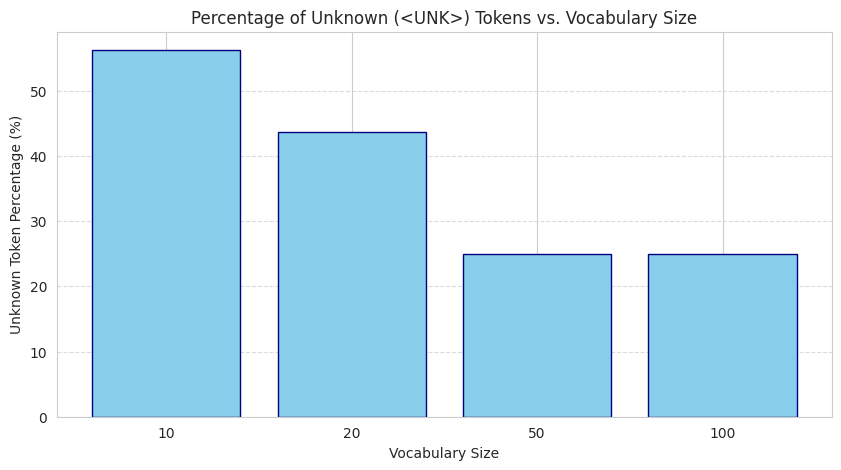

In [21]:
# YOUR CODE HERE
# Experiment with different vocabulary sizes
vocab_sizes = [10, 20, 50, 100]
test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

# For each vocabulary size, count unknown tokens
results = []
unk_id_target = None  # To keep track of UNK token ID

for size in vocab_sizes:
  # Create tokenizer with current vocab size
  tokenizer = SimpleTokenizer(vocab_size=size)
  tokenizer.build_vocab(training_texts)

  unk_id = tokenizer.word_to_id['<UNK>']

  total_tokens = 0
  unk_count = 0

  for text in test_texts:
    encoded = tokenizer.encode(text)
    total_tokens += len(encoded)
    unk_count += encoded.count(unk_id)

  unk_percentage = (unk_count / total_tokens) * 100 if total_tokens > 0 else 0
  results.append({
      'vocab_size': size,
      'total_tokens': total_tokens,
      'unk_count': unk_count,
      'unk_percentage': unk_percentage,
  })

  print(
      f'Vocab Size: {size:3d} | Total Tokens: {total_tokens:2d} | UNK Count:'
      f' {unk_count:2d} | UNK Rate: {unk_percentage:.1f}%'
  )

# Visualize results
plt.figure(figsize=(10, 5))
sizes = [r['vocab_size'] for r in results]
unk_rates = [r['unk_percentage'] for r in results]

plt.bar([str(s) for s in sizes], unk_rates, color='skyblue', edgecolor='navy')
plt.title('Percentage of Unknown (<UNK>) Tokens vs. Vocabulary Size')
plt.xlabel('Vocabulary Size')
plt.ylabel('Unknown Token Percentage (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [22]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

Word embeddings:

running (ID: 8):
  Embedding (first 5 dims): [ 0.00996514 -0.05034757 -0.15506634  0.0068563  -0.10623037]
  Norm: 0.381

coding (ID: 24):
  Embedding (first 5 dims): [-0.07591327  0.01503938  0.0341756   0.18761708  0.09504238]
  Norm: 0.442

coffee (ID: 10):
  Embedding (first 5 dims): [-0.09746817  0.07870846  0.11585956 -0.08206823  0.09633761]
  Norm: 0.345

python (ID: 12):
  Embedding (first 5 dims): [ 0.02140937 -0.12457388  0.01731809  0.03853174 -0.08838574]
  Norm: 0.315

family (ID: 14):
  Embedding (first 5 dims): [-0.04719319  0.10889506  0.006428   -0.10777448 -0.07153037]
  Norm: 0.385


### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [23]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

Training on 198 word pairs...
Epoch 0: Loss = 0.9954
Epoch 20: Loss = 0.7512
Epoch 40: Loss = 0.2963
Epoch 60: Loss = 0.0714
Epoch 80: Loss = 0.0170

✅ Embeddings trained!


In [24]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")


Words similar to 'running':
  love: 0.977
  in: 0.974
  coding: 0.960
  the: 0.947
  i: 0.945

Words similar to 'python':
  in: 0.980
  love: 0.966
  coding: 0.963
  spending: 0.943
  running: 0.943

Words similar to 'coffee':
  work: 0.982
  is: 0.979
  over: 0.979
  the: 0.975
  before: 0.966

Words similar to 'love':
  spending: 0.978
  running: 0.977
  i: 0.976
  in: 0.974
  python: 0.966


### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

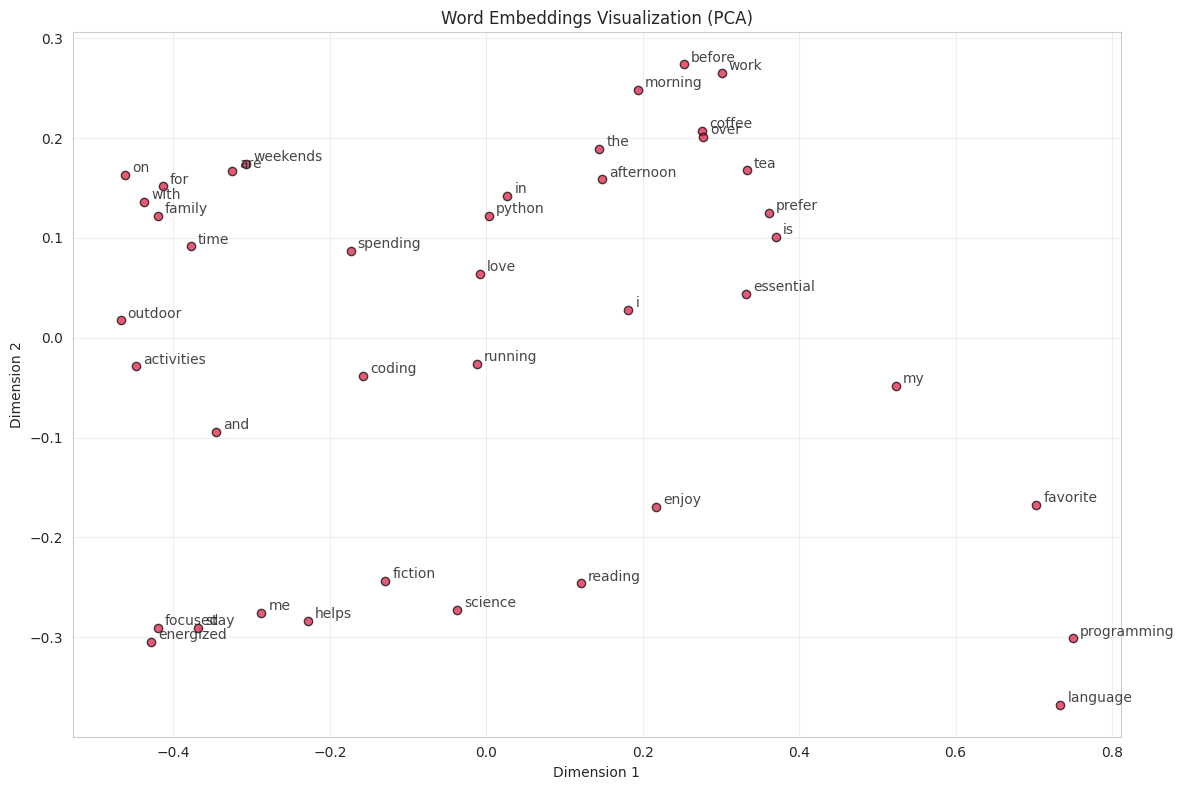

In [25]:
# YOUR CODE HERE
def visualize_embeddings(tokenizer, embeddings, method='pca'):
  """Visualize embeddings in 2D using PCA or t-SNE."""
  # Get all embeddings (excluding special tokens starting with '<')
  words = []
  vectors = []

  for word, idx in tokenizer.word_to_id.items():
    if not word.startswith('<'):
      words.append(word)
      vectors.append(embeddings.embeddings[idx])

  vectors = np.array(vectors)

  # Reduce dimensionality to 2D
  if method == 'pca':
    reducer = PCA(n_components=2)
  else:
    # Use perplexity suited for small sample sizes
    perp = min(30, max(1, len(words) - 1))
    reducer = TSNE(n_components=2, random_state=42, perplexity=perp)

  coords_2d = reducer.fit_transform(vectors)

  # Plot points
  plt.figure(figsize=(12, 8))
  plt.scatter(
      coords_2d[:, 0], coords_2d[:, 1], color='crimson', alpha=0.7, edgecolors='k'
  )

  # Annotate words on plot
  for i, word in enumerate(words):
    plt.annotate(
        word,
        (coords_2d[i, 0], coords_2d[i, 1]),
        fontsize=10,
        xytext=(5, 2),
        textcoords='offset points',
        alpha=0.85,
    )

  plt.title(f'Word Embeddings Visualization ({method.upper()})')
  plt.xlabel('Dimension 1')
  plt.ylabel('Dimension 2')
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()


# Run visualization using PCA
visualize_embeddings(tokenizer, trained_embeddings, method='pca')

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [26]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

PROCESSING THROUGH LLM PIPELINE

Step 1: Tokenization
  Input text: I love running and coding
  Tokens: ['i', 'love', 'running', 'and', 'coding']
  Token IDs: [4, 7, 8, 6, 24]

Step 2: Embedding
  Embedding shape: (5, 16)
  (sequence_length=5, embedding_dim=16)

Step 3: Contextual Processing (Simplified)
  Contextualized representation shape: (16,)

Step 4: Output Generation (Simplified)
  → In real LLMs, this produces probability distribution over vocabulary

✅ Processing complete!


### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:

**Your Answers:**

1. Why tokenization is necessary:
   - Tokenization breaks down unstructured, raw text into discrete units (tokens) and converts them into integer token IDs. Neural networks cannot process raw strings directly; they require integer indices to look up mathematical representations in an embedding lookup table.

2. Information in embeddings:
   - Embeddings capture dense semantic meaning, continuous relationships, and contextual associations between words. Words with similar meanings or shared contexts (e.g., "coffee" and "tea") end up close to each other in vector space.

3. One-hot encoding vs embeddings:
   - Using one-hot vectors creates two major issues:
   High dimensionality & sparsity: Vectors become huge (equal to vocabulary size) and consist almost entirely of zeros.

   Loss of relationships: Every one-hot vector is orthogonal to every other vector (text{dot product} = 0), so the model cannot learn that "king" and "queen" or "coding" and "python" are semantically related.

4. Sequence length impact:
   - Longer sequence lengths (N) significantly increase memory and computational cost. In Transformer architectures, attention mechanisms compute pairwise interactions between all tokens in a sequence, causing computational complexity and memory usage to grow quadratically (O(N^2)).

5. After contextual processing:
   - After tokens are updated through contextual processing layers (like self-attention and feed-forward networks), the output representations are passed through a projection layer (linear head) that produces logits over the entire vocabulary. A softmax function then converts these logits into probability distributions to predict the next token in the sequence.

### 3.2 Comparing Different Embedding Dimensions

In [27]:
# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print("Comparing embedding dimensions:\n")
for dim in dimensions:
    emb = SimpleEmbedding(vocab_size, dim)

    # Calculate memory usage
    memory_mb = (vocab_size * dim * 4) / (1024 * 1024)  # 4 bytes per float

    print(f"Dimension {dim}:")
    print(f"  Parameters: {vocab_size * dim:,}")
    print(f"  Memory: {memory_mb:.2f} MB")
    print(f"  Expressiveness: {'Low' if dim < 16 else 'Medium' if dim < 64 else 'High'}")
    print()

Comparing embedding dimensions:

Dimension 4:
  Parameters: 180
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 360
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 720
  Memory: 0.00 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 1,440
  Memory: 0.01 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [28]:
class MiniLanguageModel:
  """Simple language model for next word prediction."""

  def __init__(self, tokenizer, embeddings):
    self.tokenizer = tokenizer
    self.embeddings = embeddings

  def predict_next_word(self, context):
    """Predict the most likely next word based on embedding similarity."""
    tokens = self.tokenizer.encode(context)
    if not tokens:
      return None

    # Use the vector representation of the last context token
    last_token_id = tokens[-1]
    context_vector = self.embeddings.embeddings[last_token_id]

    best_word = None
    best_sim = -float('inf')

    # Find the most similar candidate word in the vocabulary
    for word, word_id in self.tokenizer.word_to_id.items():
      if word.startswith('<') or word_id == last_token_id:
        continue
      sim = self.embeddings.similarity(last_token_id, word_id)
      if sim > best_sim:
        best_sim = sim
        best_word = word

    return best_word

  def generate_sequence(self, start_text, num_words=5):
    """Generate a sequence of words iteratively."""
    current_text = start_text
    for _ in range(num_words):
      next_word = self.predict_next_word(current_text)
      if not next_word:
        break
      current_text += ' ' + next_word
    return current_text


# Test your model
model = MiniLanguageModel(tokenizer, trained_embeddings)

# Test 1: Next word predictions
test_contexts = ['I love', 'running in', 'python is']
print('--- Next Word Predictions ---')
for ctx in test_contexts:
  pred = model.predict_next_word(ctx)
  print(f"Context: '{ctx}' -> Predicted Next Word: '{pred}'")

# Test 2: Sequence Generation
print('\n--- Sequence Generation ---')
generated = model.generate_sequence('I love', num_words=4)
print(f"Generated text starting with 'I love':\n  \"{generated}\"")

--- Next Word Predictions ---
Context: 'I love' -> Predicted Next Word: 'spending'
Context: 'running in' -> Predicted Next Word: 'the'
Context: 'python is' -> Predicted Next Word: 'coffee'

--- Sequence Generation ---
Generated text starting with 'I love':
  "I love spending love spending love"


---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [29]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling)
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [ 0.33866163 -0.07237815  0.13469448  0.21867139 -0.04905753  0.12383126
  0.24739396 -0.10105272]

Comparing User Profiles:

User 1 vs User 2 similarity: 0.985
User 1 vs User 3 similarity: 0.988
User 2 vs User 3 similarity: 0.968

Detected Interests:

User 1: ['and', 'i', 'coffee', 'running', 'love']
User 2: ['and', 'in', 'i', 'python', 'enjoy']
User 3: ['and', 'in', 'i', 'running', 'love']


### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [30]:
# YOUR CODE HERE
# 1. Write a detailed description of yourself
my_description = "I am a computer science student who loves web development, coding in Python, and data analysis. I enjoy classic literature and watching football on weekends."

# 2. Encode it using the digital twin encoder
my_profile = twin_encoder.encode_user(my_description)
print("=== My Profile Encoding ===")
print(f"Profile Vector Shape: {my_profile.shape}")
print(f"Profile Vector (First 8 Dims): {my_profile[:8]}\n")

# 3. Compare it with other example profiles
print("=== Profile Similarities ===")
sim_to_user1 = twin_encoder.compare_descriptions(my_description, user1)
sim_to_user2 = twin_encoder.compare_descriptions(my_description, user2)
sim_to_user3 = twin_encoder.compare_descriptions(my_description, user3)

print(f"Similarity to User 1 (Outdoors & Coffee): {sim_to_user1:.3f}")
print(f"Similarity to User 2 (Coding & AI):        {sim_to_user2:.3f}")
print(f"Similarity to User 3 (Running & Python):    {sim_to_user3:.3f}\n")

# 4. Identify detected interests
my_interests = twin_encoder.find_interests(my_description)
print("=== Detected Interests ===")
print(f"Key Interest Tokens: {my_interests}\n")

# 5. Test how similar descriptions affect similarity scores
similar_desc = "I am a CS student into programming, software engineering, and reading books."
different_desc = "I love cooking pasta, baking bread, and preparing morning breakfasts."

sim_high = twin_encoder.compare_descriptions(my_description, similar_desc)
sim_low = twin_encoder.compare_descriptions(my_description, different_desc)

print("=== Sensitivity Test ===")
print(f"Similarity to Similar Tech Profile:  {sim_high:.3f}")
print(f"Similarity to Unrelated Food Profile: {sim_low:.3f}")


=== My Profile Encoding ===
Profile Vector Shape: (16,)
Profile Vector (First 8 Dims): [ 0.23385009  0.00761114  0.16579554  0.15624987 -0.10854767  0.00024672
  0.11937249 -0.05429813]

=== Profile Similarities ===
Similarity to User 1 (Outdoors & Coffee): 0.878
Similarity to User 2 (Coding & AI):        0.926
Similarity to User 3 (Running & Python):    0.811

=== Detected Interests ===
Key Interest Tokens: ['and', 'and', 'in', 'i', 'i']

=== Sensitivity Test ===
Similarity to Similar Tech Profile:  0.897
Similarity to Unrelated Food Profile: 0.994


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

Vocabulary built: 56 tokens
Training on 220 word pairs...
Epoch 0: Loss = 1.0079
Epoch 20: Loss = 0.8235
Epoch 40: Loss = 0.4311
Epoch 60: Loss = 0.1302
Epoch 80: Loss = 0.0352
Epoch 100: Loss = 0.0116

=== USER SIMILARITY MATRIX ===

=== RECOMMENDATIONS (Top Recommended Connections) ===
User 'Alice' -> Recommended Connection: 'Eve' (Match Score: 0.810)
User 'Bob' -> Recommended Connection: 'Frank' (Match Score: 0.942)
User 'Charlie' -> Recommended Connection: 'Frank' (Match Score: 0.989)
User 'Diana' -> Recommended Connection: 'Charlie' (Match Score: 0.705)
User 'Eve' -> Recommended Connection: 'Alice' (Match Score: 0.810)
User 'Frank' -> Recommended Connection: 'Charlie' (Match Score: 0.989)


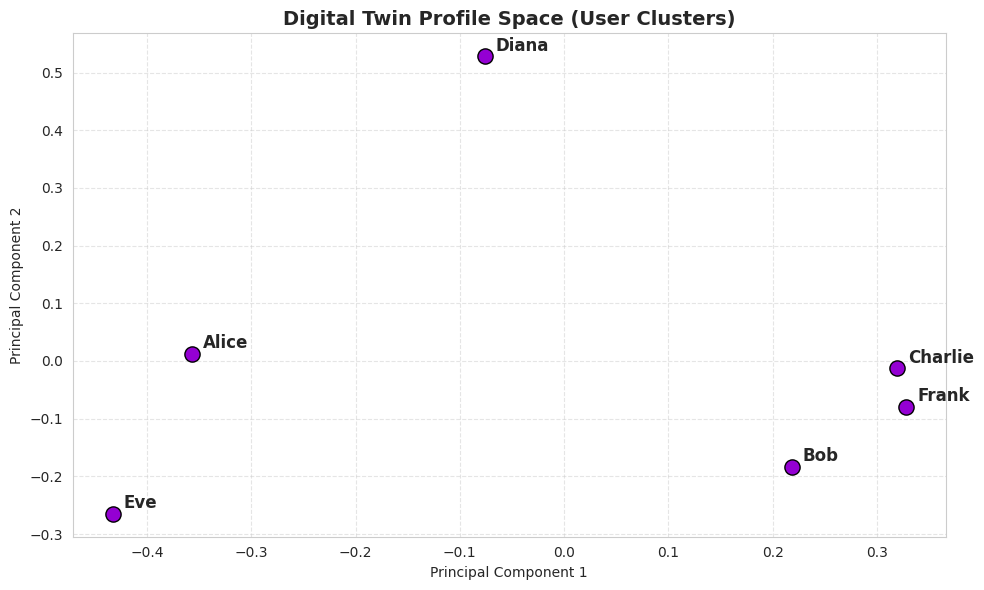

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# 1. DATA COLLECTION: Gather multiple user descriptions
user_database = {
    'Alice': (
        'I am a software engineer building AI models and coding in Python'
        ' daily.'
    ),
    'Bob': (
        'Data analyst who loves Python programming, SQL databases, and'
        ' statistics.'
    ),
    'Charlie': (
        'Fitness enthusiast who enjoys outdoor running, marathon training, and'
        ' hiking.'
    ),
    'Diana': (
        'Avid reader of classic literature, poetry, and philosophy books.'
    ),
    'Eve': (
        'Web developer focused on frontend coding, UI design, and JavaScript.'
    ),
    'Frank': (
        'Coffee lover who spends weekends running in the park and outdoor'
        ' sports.'
    ),
}

# Collect descriptions into a list
all_descriptions = list(user_database.values())
user_names = list(user_database.keys())

# 2. TRAINING: Build tokenizer and train embeddings on the dataset
challenge_tokenizer = SimpleTokenizer(vocab_size=100)
challenge_tokenizer.build_vocab(all_descriptions)

challenge_embeddings = train_embeddings(
    tokenizer=challenge_tokenizer,
    texts=all_descriptions,
    embedding_dim=16,
    epochs=120,
    learning_rate=0.01,
)

# Initialize encoder using the freshly trained embeddings
challenge_encoder = DigitalTwinEncoder(
    challenge_tokenizer, challenge_embeddings
)

# Encode all profiles into a feature matrix
profile_vectors = []
for desc in all_descriptions:
  vector = challenge_encoder.encode_user(desc)
  profile_vectors.append(vector)

profile_matrix = np.array(profile_vectors)

# 3. CLUSTERING & SIMILARITY SEARCH: Find similar users
print('\n=== USER SIMILARITY MATRIX ===')
similarity_matrix = np.zeros((len(user_names), len(user_names)))

for i, name1 in enumerate(user_names):
  for j, name2 in enumerate(user_names):
    sim = challenge_encoder.compare_descriptions(
        user_database[name1], user_database[name2]
    )
    similarity_matrix[i, j] = sim

# Print top connection for each user
print('\n=== RECOMMENDATIONS (Top Recommended Connections) ===')
for i, name in enumerate(user_names):
  # Get indices sorted by similarity score (excluding self-match)
  scores = similarity_matrix[i].copy()
  scores[i] = -1.0  # Mask self-similarity
  best_match_idx = np.argmax(scores)
  best_match_name = user_names[best_match_idx]
  best_score = scores[best_match_idx]

  print(
      f"User '{name}' -> Recommended Connection: '{best_match_name}' (Match"
      f' Score: {best_score:.3f})'
  )

# 4. VISUALIZATION: Create 2D plot of user embedding space using PCA
pca = PCA(n_components=2)
coords_2d = pca.fit_transform(profile_matrix)

plt.figure(figsize=(10, 6))
plt.scatter(
    coords_2d[:, 0],
    coords_2d[:, 1],
    color='darkviolet',
    s=120,
    edgecolors='black',
    zorder=3,
)

for i, name in enumerate(user_names):
  plt.annotate(
      name,
      (coords_2d[i, 0], coords_2d[i, 1]),
      fontsize=12,
      fontweight='bold',
      xytext=(8, 4),
      textcoords='offset points',
  )

plt.title(
    'Digital Twin Profile Space (User Clusters)', fontsize=14, fontweight='bold'
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
